# 36 — SARIMA × SARIMAX com seleção independente no `statsmodels`

Análise principal: SARIMA e SARIMAX sazonais por UF e período, usando exógenas selecionadas **por suporte/posto no treinamento**. Análise complementar: nacional com as 16 tipologias simultaneamente, quando identificáveis.

O `statsmodels` **não possui seleção automática de ordens** na classe SARIMAX. Por isso, este notebook usa uma busca explícita sobre cinco especificações sazonais, estimadas separadamente com e sem exógenas, selecionando a menor BIC convergida no treino.

A previsão é condicional de um passo: usa desastres contemporâneos observados, não prevê a ocorrência futura de desastres.

## 1. Verificação do painel e da disponibilidade dos resultados

In [1]:
from pathlib import Path
import os, sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd()
sys.path.insert(0,str(ROOT/'src'))
if 'TCC_BASE_CSV' not in os.environ:
    os.environ['TCC_BASE_CSV']=str(ROOT/'data/processed/df_tcc_2013_2024.csv')
from analise_estadual import load, TIPOS
D=ROOT/'outputs/tables/revisao_estadual_20261019'
A=ROOT/'outputs/tables/auditoria_metodologica_20261020'
S=ROOT/'outputs/tables/sarimax_criterios_independentes_20261020'
df=load()
print(f'Painel: {len(df)} observações, {df.uf.nunique()} UFs, {df.mes_ano.nunique()} meses, {len(TIPOS)} tipologias')

Painel: 3888 observações, 27 UFs, 144 meses, 16 tipologias


## 2. Execução/reexecução dos candidatos sazonais

A rotina foi executada com `statsmodels`, registrando avisos, convergência e BIC por candidato. Para repetir integralmente do zero, exclua os CSVs de checkpoint e rode novamente os quatro comandos abaixo. O reprocessamento incremental não reestima combinações que já estejam salvas.

O **SARIMA e SARIMAX são escolhidos separadamente** por BIC; uma comparação pareada com ordens iguais é armazenada como análise complementar.

In [2]:
from selecionar_sarima_sarimax_statsmodels import run
# Reprocessamento incremental seguro: preserva resultados por UF concluída.
for mode in ('nacional','estadual'):
    for period in ('Pré','Total'):
        run(mode,period)

REANUDANDO nacional Pré concluidos= 1


DONE nacional Pré modelos 1 tempo 0.012247437999917565


REANUDANDO nacional Total concluidos= 1


DONE nacional Total modelos 1 tempo 0.00816818400005559


REANUDANDO estadual Pré concluidos= 27


DONE estadual Pré modelos 27 tempo 0.012656365999987429


REANUDANDO estadual Total concluidos= 27


DONE estadual Total modelos 27 tempo 0.02118017800000871


## 3. BH global, sumários e warnings

In [3]:
from consolidar_analises_finais import sarimax as consolidar
consolidar()
from pathlib import Path
import json
for modo in ['estadual','nacional']:
    resumo=json.loads((S/f'{modo}_resumo_final.json').read_text())
    print(modo.upper(),resumo)
    print('Significativos após BH global:')
    cs=pd.read_csv(S/f'{modo}_significativos_BH.csv')
    print(cs[['unidade','periodo','tipologia','coef_original','p_individual','q_individual_BH_global']].to_string(index=False) if len(cs) else 'Nenhum')

estadual {"modo": "estadual", "total_unidades_periodos": 54, "comparaveis": 53, "melhora_RMSE": 16, "melhora_BIC": 0, "mediana_melhora_RMSE_pct": -5.10296132054755, "sazonal_em_todos_candidatos": true, "busca_independente": true, "melhor_entre_5_candidatos_por_BIC": true, "diagnostico_LB_SARIMA_rejeita": 14, "diagnostico_LB_SARIMAX_rejeita": 13, "candidatos_total": 530, "candidatos_com_warnings": 38, "candidatos_nao_convergentes": 0, "coeficientes_totais": 395, "coeficientes_nominais": 14, "coeficientes_BH_global": 2, "testes_conjuntos_BH": 0, "proveniencia": "df_tcc_2013_2024.csv SHA256 46f4f8408f5f6a809de2601b5c313ea52ee5992ed5a65ede5246c57d28767e36", "observacoes": "Testes condicionais à seleção por BIC; exógenas contemporâneas observadas no teste."}
nacional {"modo": "nacional", "total_unidades_periodos": 2, "comparaveis": 2, "melhora_RMSE": 0, "melhora_BIC": 0, "mediana_melhora_RMSE_pct": -12.803545739821786, "sazonal_em_todos_candidatos": true, "busca_independente": true, "melhor

## 4. Auditoria: 16 tipologias por UF versus série nacional

In [4]:
old=pd.read_csv(ROOT/'outputs/tables/sarimax_revisao_20261019/estadual_auditoria_posto.csv')
print(old.groupby('periodo').agg(casos=('posto_treino','size'),posto16_treino=('posto_treino',lambda x:(x==16).sum()),posto16_total=('posto_completo',lambda x:(x==16).sum())).to_string())
new=pd.concat([pd.read_csv(S/f'nacional_{period}_modelos.csv') for period in ('Pré','Total')])
print('BIC e RMSE NACIONAL:')
print(new[['periodo','ordem_sarima','ordem_sarimax','delta_BIC','rmse_sarima','rmse_sarimax','melhora_RMSE_pct','p_conjunto_condicional']].to_string(index=False))

         casos  posto16_treino  posto16_total
periodo                                      
Pré         27               0              0
Total       27               1              5
BIC e RMSE NACIONAL:
periodo ordem_sarima ordem_sarimax  delta_BIC  rmse_sarima  rmse_sarimax  melhora_RMSE_pct  p_conjunto_condicional
    Pré    (0, 0, 0)     (0, 0, 0)  55.023443     1.866172      2.146544        -15.023915                0.643079
  Total    (1, 0, 1)     (1, 0, 1)  64.107716     1.354183      1.497498        -10.583177                0.718972


## 5. Comparação estadual e diagnóstico Ljung–Box

Comparações estaduais: 53 melhora RMSE: 16 melhora BIC: 0
Rejeições do LB SARIMA: 14 SARIMAX: 13
Melhorias mais expressivas:
unidade periodo  n_exog  melhora_RMSE_pct  delta_BIC
     MS   Total    12.0         13.503419  44.658230
     AP   Total     6.0          8.359901  22.127544
     PI     Pré     2.0          7.891005   8.225408
     AC   Total     8.0          7.529285  36.230190
     PR     Pré     9.0          6.834091  35.633220
     SE   Total     9.0          6.298866  31.286088
     RJ     Pré     9.0          5.087320  27.961160
     TO     Pré     3.0          4.698240  11.055844
     AM   Total     9.0          4.580963  32.170161
     MA     Pré     5.0          3.380049  20.694344


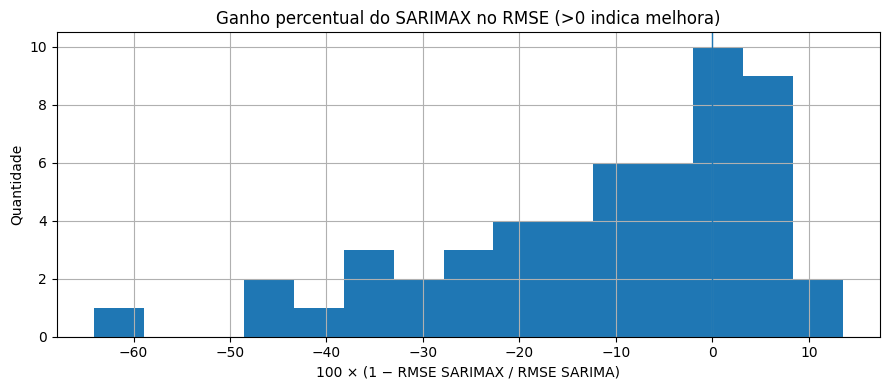

In [5]:
st=pd.read_csv(S/'estadual_comparacao.csv')
print('Comparações estaduais:',int(st.rmse_sarimax.notna().sum()),'melhora RMSE:',int((st.melhora_RMSE_pct>0).sum()),'melhora BIC:',int((st.delta_BIC<0).sum()))
print('Rejeições do LB SARIMA:',int((st.ljungbox_sarima<.05).sum()),'SARIMAX:',int((st.ljungbox_sarimax<.05).sum()))
print('Melhorias mais expressivas:')
print(st.nlargest(10,'melhora_RMSE_pct')[['unidade','periodo','n_exog','melhora_RMSE_pct','delta_BIC']].to_string(index=False))
fig,ax=plt.subplots(figsize=(9,4))
pd.to_numeric(st.melhora_RMSE_pct,errors='coerce').dropna().hist(ax=ax,bins=15)
ax.axvline(0,linewidth=1);ax.set_title('Ganho percentual do SARIMAX no RMSE (>0 indica melhora)')
ax.set_xlabel('100 × (1 − RMSE SARIMAX / RMSE SARIMA)');ax.set_ylabel('Quantidade');plt.tight_layout();plt.show()

## 6. Warnings e convergência

Warnings de inicialização AR/MA foram preservados para auditoria. Eles não significam necessariamente falha de ajuste; não convergência final, posto deficiente e rejeição Ljung–Box têm significados distintos.

In [6]:
for mode in ('estadual','nacional'):
    W=pd.read_csv(S/f'{mode}_warnings.csv')
    models=pd.read_csv(S/f'{mode}_comparacao.csv')
    print(mode,'candidatos com warnings',len(W),'modelos com LB SARIMAX rejeitado',int((models.ljungbox_sarimax<.05).sum()))
    print(W[['periodo','unidade','modelo','ordem','n_warnings','warnings']].head(8).to_string(index=False,max_colwidth=90))

estadual candidatos com warnings 38 modelos com LB SARIMAX rejeitado 13
periodo unidade  modelo     ordem  n_warnings                                                                                   warnings
    Pré      AL  SARIMA (1, 0, 1)           1 UserWarning: Non-invertible starting MA parameters found. Using zeros as starting param...
    Pré      AL SARIMAX (1, 0, 1)           2 UserWarning: Non-invertible starting MA parameters found. Using zeros as starting param...
    Pré      AM  SARIMA (1, 0, 1)           2 UserWarning: Non-invertible starting MA parameters found. Using zeros as starting param...
    Pré      BA SARIMAX (1, 0, 1)           2 UserWarning: Non-invertible starting MA parameters found. Using zeros as starting param...
    Pré      CE  SARIMA (1, 0, 1)           2 UserWarning: Non-invertible starting MA parameters found. Using zeros as starting param...
    Pré      CE SARIMAX (1, 0, 1)           2 UserWarning: Non-invertible starting MA parameters found. Us

## 7. Interpretação

O modelo estadual reduzido é condicionado ao suporte das tipologias em cada UF. O nacional contém as 16 tipologias sem agrupá-las. A escolha independente por BIC pode modificar a ordem SARIMA da comparação e os resultados preditivos frente à versão que forçava a mesma ordem. Os testes individuais e conjuntos são exploratórios porque não incorporam formalmente a seleção de ordens e regressores. Nenhuma diferença de BIC positiva indica evidência favorável à complexidade adicional das exógenas.